# 2. Classifying verses as Meccan or Medinan, honestly

A *classifier* is a program that learns to sort things into categories from labelled examples. Here the things are verses and the categories are "Meccan" and "Medinan". We show it thousands of verses with their labels; it learns which features go with which label; then we test it on verses it has **never seen**.

This notebook does three things:

1. puts the 2017 version's headline number in context, and shows a trap it avoided;
2. compares several kinds of evidence (length, style, vocabulary, English translation) fairly;
3. looks at the surahs where the model and the tradition disagree, which is where the historically interesting questions are.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from surahs import load_verses, load_surah_texts
from surahs.models import make_model, baseline_model, cross_validate, top_features
from surahs.features import FEATURE_DESCRIPTIONS
from surahs.translit import translit
from surahs.plotting import PERIOD_STYLE, style_axes

verses = load_verses()
surahs = load_surah_texts()

## 2.1 What "accuracy" hides

About 74% of verses come from surahs the Cairo edition calls Meccan. So a "classifier" that ignores the text and always answers *Meccan* is already 74% accurate. The 2017 version reported 86% accuracy. That sounds good until you compare it with 74%.

We therefore use **balanced accuracy**: the average of "% of Meccan verses called Meccan" and "% of Medinan verses called Medinan". Always answering *Meccan* scores 50%, exactly what a coin flip would get. We also report **AUC**: the probability that the model ranks a randomly chosen Medinan item above a randomly chosen Meccan one. 0.5 is chance; 1.0 is perfect.

In [2]:
y = (verses.cairo_place == "Medinan").astype(int)
print(f"Always answering 'Meccan' is {1 - y.mean():.1%} accurate")

Always answering 'Meccan' is 74.0% accurate


## 2.2 Leakage: the most common mistake in text classification

Verses of the same surah share rhyme, vocabulary and topic. If verses 2:1–2:200 are in the training set and 2:201–2:286 in the test set, the model can recognise *al-Baqara*, not *Medina*.

The fix is to keep each surah entirely on one side of the split: **grouped cross-validation**. Cross-validation means we split the data five ways, train on four parts, test on the fifth, and rotate, so that every verse is tested exactly once by a model that never saw it.

The 2017 version got this right: it split by surah, so that refrains like the one repeated 31 times in surah 55 could not appear on both sides. But it used a *single* random split. The cell after next repeats that split 20 times to show how much the one reported number could have wobbled.

First, the leak itself. Compare a leaky verse-level split with a grouped one, using the 2017 model (raw word counts, plain logistic regression).

In [3]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, balanced_accuracy_score

X = CountVectorizer(token_pattern=r"\S+").fit_transform(verses.text)
for name, cv in [("leaky: random verses", KFold(5, shuffle=True, random_state=0)),
                 ("honest: whole surahs", GroupKFold(5))]:
    pred = cross_val_predict(LogisticRegression(max_iter=5000), X, y, cv=cv, groups=verses.surah)
    print(f"{name:22s} accuracy {accuracy_score(y, pred):.3f}   balanced accuracy {balanced_accuracy_score(y, pred):.3f}")

leaky: random verses   accuracy 0.867   balanced accuracy 0.786


honest: whole surahs   accuracy 0.845   balanced accuracy 0.750


In [4]:
from sklearn.model_selection import train_test_split
accs = []
for seed in range(20):
    train_surahs, _ = train_test_split(np.arange(1, 115), train_size=0.4, random_state=seed)
    tr = verses.surah.isin(train_surahs).to_numpy()
    m = LogisticRegression(max_iter=5000).fit(X[tr], y[tr])
    accs.append(m.score(X[~tr], y[~tr]))
print(f"2017 set-up, 20 different random splits: accuracy from {min(accs):.1%} to {max(accs):.1%}")

2017 set-up, 20 different random splits: accuracy from 76.6% to 89.2%


**Question 2.1.** In your own words, why is the leaky number higher? Would the same problem arise if you were classifying letters in an archive by decade, and some letters were drafts of each other?

## 2.3 Which kind of evidence matters?

Now we compare feature sets, each with the same classifier (class-balanced logistic regression) and the same honest evaluation. "Surah" columns average the verse predictions inside each surah, because the label really belongs to the surah.

This takes a minute or two.

In [5]:
rows, runs = [], {}
for name in ["baseline", "length", "style", "words", "lemmas", "roots", "chars", "english"]:
    model = baseline_model() if name == "baseline" else make_model(name)
    r = cross_validate(model, verses, "cairo_place", seeds=(0,), name=name)
    runs[name] = r
    rows.append({"features": name, "what it is": FEATURE_DESCRIPTIONS.get(name, "always 'Meccan'"),
                 "verse bal. acc.": r.verse_metrics["balanced_accuracy"], "verse AUC": r.verse_metrics["roc_auc"],
                 "surah bal. acc.": r.surah_metrics["balanced_accuracy"], "surah AUC": r.surah_metrics["roc_auc"]})
pd.DataFrame(rows).round(3)

,features,what it is,verse bal. acc.,verse AUC,surah bal. acc.,surah AUC
0,baseline,always 'Meccan',0.500,0.500,0.500,0.500
1,length,"Verse length only (letters, words)",0.701,0.772,0.789,0.904
2,style,Length + rhyme + divine names + forms of address,0.736,0.811,0.876,0.924
3,words,Bag of Arabic surface words (the 2017 approach),0.778,0.845,0.893,0.915
4,lemmas,Bag of lemmas incl. function words,0.786,0.846,0.917,0.906
5,roots,Bag of consonantal roots,0.765,0.828,0.929,0.920
6,chars,Character 2-5-grams,0.801,0.866,0.911,0.920
7,english,Bag of English words (Pickthall translation),0.782,0.849,0.905,0.920


Things to notice:

- **Length alone** (three numbers per verse!) gets a surah-level AUC around 0.9. Most of what any model "learns" is that Medinan verses are long.
- Vocabulary-based models do better at the verse level, where length is a noisier signal, but at the surah level they add surprisingly little on top of length.
- The **English translation** works about as well as the Arabic. A classifier does not need to "understand" Arabic to pick up these regularities, which should make you ask what it *is* picking up.

**Question 2.2.** Sinai and others argue that verse length is a reasonable rough proxy for date. If length explains most of the classifier's success, what does that imply about claims that a model has "learned to recognise Medinan revelation"?

## 2.4 What does the vocabulary model rely on?

A logistic regression gives every feature a *weight*. Positive weights push towards Medinan, negative towards Meccan. We fit the lemma model on all the data and list the strongest. Look up any lemma at corpus.quran.com: the dictionary there gives meanings and every occurrence.

In [6]:
model = make_model("lemmas").fit(verses, y)
tf = top_features(model, 15)
tf["transliteration"] = tf.feature.map(translit)
tf

,points_towards,feature,weight,transliteration
0,Meccan,جَعَلَ,-2.053719,jaʿala
1,Meccan,أ,-2.043558,ʾ
2,Meccan,عَبْد,-1.991439,ʿabd
3,Meccan,وَعْد,-1.975370,waʿd
4,Meccan,عَبَدَ,-1.829366,ʿabada
5,Meccan,قالَ,-1.786749,qala
6,Meccan,آيَة,-1.573469,ʾāya
7,Meccan,أَكْثَر,-1.522326,ʾakthar
8,Meccan,حَمْد,-1.457022,ḥamd
9,Meccan,دُون,-1.364366,dūn


Look at *ālāʾ* ("favours", آلاء) high on the Medinan side. It comes almost entirely from one refrain, "Which, then, of the favours of your Lord will you deny?", repeated 31 times in surah 55. The Cairo edition calls surah 55 Medinan, so a model fitted on all the data learns "favours = Medinan". That is a fact about one label, not about Medina.

**Question 2.3.** Which of these words would a historian *expect* to be Medinan (think: fighting, hypocrites, the community's laws)? Which are surprising? Are any of them just grammar?

## 2.5 Where the model and the tradition part ways

Every surah now has a probability of being Medinan from a model that **never saw that surah during training**. The plot puts surahs in Nöldeke's order and marks the four disputed surahs and every surah the model gets "wrong" according to the Cairo labels.

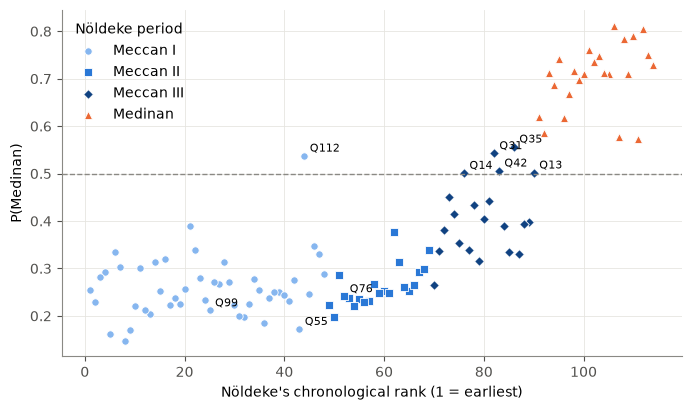

In [7]:
p = runs["lemmas"].surah_proba
s = surahs.assign(p_medinan=p)
fig, ax = plt.subplots(figsize=(8, 4.5))
for period, st in PERIOD_STYLE.items():
    g = s[s.noldeke_period == period]
    ax.scatter(g.noldeke_order, g.p_medinan, label=period, **st)
flag = s.labels_disagree | ((s.p_medinan > 0.5) != (s.cairo_place == "Medinan"))
for n in s.index[flag]:
    ax.annotate(f"Q{n}", (s.noldeke_order[n], s.p_medinan[n]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.axhline(0.5, color="#8a8984", lw=1, ls="--")
ax.set_xlabel("Nöldeke's chronological rank (1 = earliest)"); ax.set_ylabel("P(Medinan)")
style_axes(ax); ax.legend(frameon=False, title="Nöldeke period", loc="upper left");

In [8]:
s.loc[flag, ["name_translit", "cairo_place", "noldeke_period", "p_medinan", "mvl"]].sort_values("p_medinan").round(2)

,name_translit,cairo_place,noldeke_period,p_medinan,mvl
surah,,,,,
55,Ar-Rahmaan,Medinan,Meccan I,0.17,21.12
99,Az-Zalzala,Medinan,Meccan I,0.21,19.75
76,Al-Insaan,Medinan,Meccan II,0.24,35.06
14,Ibrahim,Meccan,Meccan III,0.50,68.06
13,Ar-Ra'd,Medinan,Meccan III,0.50,82.44
42,Ash-Shura,Meccan,Meccan III,0.51,66.45
112,Al-Ikhlaas,Meccan,Meccan I,0.54,11.75
31,Luqman,Meccan,Meccan III,0.54,63.85
35,Faatir,Meccan,Meccan III,0.56,71.96


The 2017 notebook listed surahs 13, 22, 47, 55, 76 and 99 as "misclassified". Four of those six are precisely the surahs where Nöldeke disagrees with the Cairo edition. The model wasn't failing there. It was siding with Nöldeke, because Nöldeke's judgments were largely based on the same kind of linguistic evidence the model uses. A fifth, surah 22, is Medinan in both systems, but Sinai (2017) argues it is a composite with a large block of Meccan material taken into a Medinan surah. A label for the whole surah can't express that.

**Question 2.4.** Pick one surah from the table above. Read it in English. Then find out what Islamic tradition says about where it was revealed (a good start: the introduction to the surah in *The Study Quran*, ed. S. H. Nasr et al., 2015). Is the model's disagreement a problem for the model, the label, or neither? Note: the Cairo edition labels *whole surahs*, but its headings also list individual verses that it considers exceptions (e.g. Medinan verses in a Meccan surah). Our labels ignore those exceptions.

## 2.6 Verses the tradition singles out

The Cairo edition labels whole surahs, but its surah headings also list *exceptions*: individual verses said to come from the other city. Surah 73, for instance, is "Meccan, except verses 10, 11 and 20, which are Medinan." We have these lists (from the Tanzil Project) in the column `is_exception`.

Our models were trained on whole-surah labels and never saw the surah being tested, so they know nothing about these lists. Do they nonetheless score the exception verses as more Medinan than the verses around them?

In [9]:
from sklearn.metrics import roc_auc_score
has_ex = verses[(verses.cairo_place == "Meccan") & verses.surah.isin(verses.loc[verses.is_exception, "surah"])]
print(has_ex.surah.nunique(), "Meccan surahs with", has_ex.is_exception.sum(), "'Medinan' exception verses")
for name in ["length", "lemmas", "chars"]:
    p = runs[name].verse_proba.loc[has_ex.index]
    print(f"{name:8s} AUC {roc_auc_score(has_ex.is_exception, p):.2f}")

33 Meccan surahs with 148 'Medinan' exception verses
length   AUC 0.54
lemmas   AUC 0.60
chars    AUC 0.61


An AUC of 0.5 would mean the model can't tell exception verses from their neighbours at all; 1.0 would mean it always ranks them higher. The vocabulary models score about 0.6: a weak signal. Length alone barely gets above chance.

**Question 2.5.** Pick one exception (try 73:20, which Sinai and Neuwirth also regard as a later addition, or 29:1–11). Read it in English beside the verses around it. Does it *feel* different? What evidence would you need to decide whether the tradition is right about it?

## 2.7 Try it yourself

1. Rerun section 2.3 with `"noldeke_place"` instead of `"cairo_place"`. Which feature sets improve? Why might that be?
2. In `src/surahs/features.py`, the `style` feature set includes counts of three divine names. Add a fourth marker of your choice (for instance a lemma you saw in 2.4) and see whether it helps.